In [1]:
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve
import statsmodels.api as sm

import pickle

import xgboost as xgb
print(xgb.__version__)

3.2.0


In [2]:
train = pd.read_csv('../Data/train_features_imputed.csv')
oot1 = pd.read_csv('../Data/oot1_features_imputed.csv')
oot2 = pd.read_csv('../Data/oot2_features_imputed.csv')

all_features = pickle.load(open('../Files/all_features.pkl', 'rb'))
identifier_cols = all_features['identifier_features']
features_to_select = pickle.load(open('../Files/selected_features_before_vif.csv', 'rb'))['final_selected_features_before_vif']

In [3]:
def get_scores(df, features, model, ID_cols):
    return pd.concat([
        df[ID_cols], pd.DataFrame({
            'y_true': df['default'],
            'y_pred': model.predict_proba(df[features])[:,1]
        })
    ], axis=1)

In [4]:
clf = xgb.XGBClassifier(
    objective='binary:logistic',
    eval_metric='auc',
    use_label_encoder=False,
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    enable_categorical=True,
    early_stopping_rounds=50
)

In [5]:
feature_set_1 = ['net_loss_flag',
 'account_payables_to_assets',
 'st_debt_share',
 'receivables_to_assets',
 'nonpositive_ebitda_flag',
 'operating_loss_flag',
 'negative_equity_flag',
 'cash_to_assets',
 'equity_to_assets',
 'net_profit_to_assets']
len(feature_set_1)

10

In [6]:
clf.fit(
    train[feature_set_1], train['default'],
    eval_set=[(train[feature_set_1], train['default']), (oot1[feature_set_1], oot1['default'])],
    verbose=50
)

[0]	validation_0-auc:0.76754	validation_1-auc:0.75204


/opt/homebrew/Caskroom/miniconda/base/envs/nlp/lib/python3.10/site-packages/xgboost/callback.py:385: UserWarning: [18:03:33] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  self.starting_round = model.num_boosted_rounds()


[50]	validation_0-auc:0.82456	validation_1-auc:0.80044
[100]	validation_0-auc:0.83432	validation_1-auc:0.80147
[133]	validation_0-auc:0.83905	validation_1-auc:0.80113


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=50,
              enable_categorical=True, eval_metric='auc', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=500,
              n_jobs=None, num_parallel_tree=None, ...)

In [7]:
scores_train = get_scores(train, feature_set_1, clf, identifier_cols)
scores_oot1 = get_scores(oot1, feature_set_1, clf, identifier_cols)
scores_oot2 = get_scores(oot2, feature_set_1, clf, identifier_cols)

print(f'Train AUC: {roc_auc_score(scores_train["y_true"], scores_train["y_pred"]):.4f}')
print(f'OOT1 AUC: {roc_auc_score(scores_oot1["y_true"], scores_oot1["y_pred"]):.4f}')
print(f'OOT2 AUC: {roc_auc_score(scores_oot2["y_true"], scores_oot2["y_pred"]):.4f}')

Train AUC: 0.8317
OOT1 AUC: 0.8016
OOT2 AUC: 0.8210


In [8]:
import shap

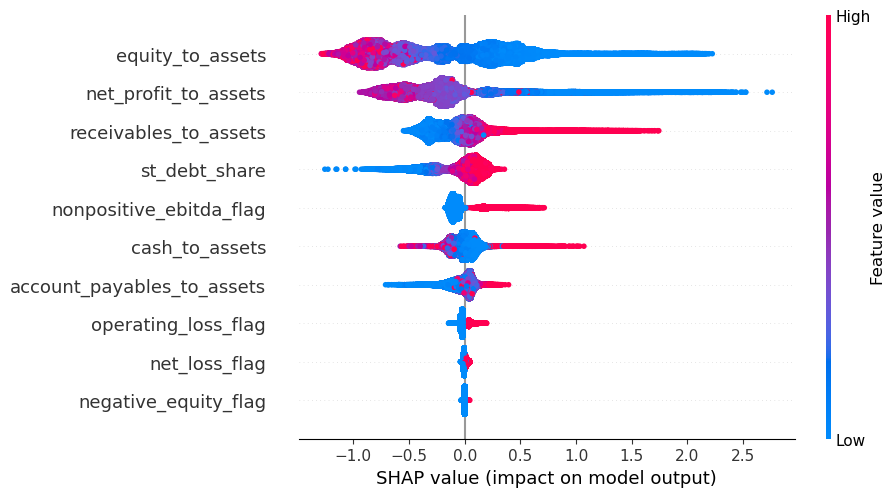

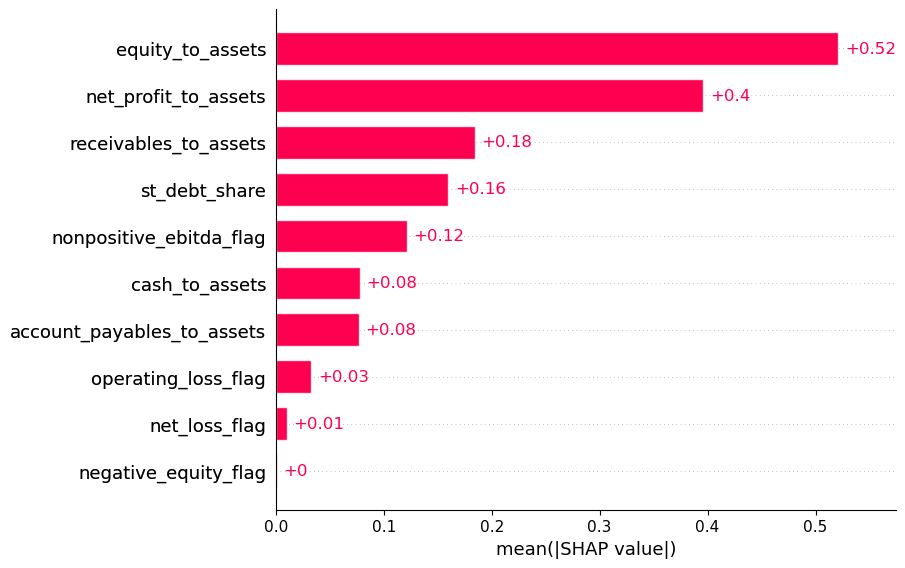

In [10]:
X_shap = oot2[feature_set_1].sample(n=len(oot2), random_state=42)

dmatrix = xgb.DMatrix(
    X_shap,
    feature_names=feature_set_1,
    enable_categorical=True
)

# Match the early-stopped clf's best iteration
contributions = clf.get_booster().predict(
    dmatrix,
    pred_contribs=True,
    iteration_range=(0, clf.best_iteration + 1)
)

# The final column is the base value; the others are feature SHAP values
shap_values = shap.Explanation(
    values=contributions[:, :-1],
    base_values=contributions[:, -1],
    data=X_shap.to_numpy(),
    feature_names=feature_set_1
)

shap.plots.beeswarm(shap_values, max_display=len(feature_set_1))
shap.plots.bar(shap_values, max_display=len(feature_set_1))